# Summative - Regression Analysis Mobile Application
## Predicting Food Prices in Sudanese Markets During the War

**Use case:** Aid agencies such as WFP give families cash to buy food. Since the war began in April 2023, prices differ sharply between markets and months. This model predicts the retail price of a food item (USD per kg) for a given market and month, to help set fair cash-transfer amounts.

# Step one: Explore and prepare the data

## 1. Imports 

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Load the data 
Source: WFP Sudan food prices, from HDX.

In [2]:
df = pd.read_csv("wfp_food_prices_sdn.csv")
print(df.shape)
df.head()


(23384, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2001-01-15,Blue Nile,Damazin,Damazin,1026,11.79,34.36,cereals and tubers,Sorghum (white),135,90 KG,actual,Wholesale,SDG,46.00,17.76
1,2001-01-15,Gedaref,Al Gedaref Rural,El Gedarif,2580,14.04,35.38,cereals and tubers,Sorghum (white),135,90 KG,actual,Wholesale,SDG,51.67,19.95
2,2001-01-15,Khartoum,Jebal Aulya,Khartoum,2588,15.51,32.54,cereals and tubers,Millet,73,90 KG,actual,Wholesale,SDG,77.29,29.84
3,2001-01-15,Khartoum,Jebal Aulya,Khartoum,2588,15.51,32.54,cereals and tubers,Sorghum (white),135,90 KG,actual,Wholesale,SDG,63.90,24.67
4,2001-01-15,Khartoum,Jebal Aulya,Khartoum,2588,15.51,32.54,cereals and tubers,Wheat,84,90 KG,actual,Wholesale,SDG,81.50,31.47


## 3. Filter to the war period
Keep prices from 15 April 2023 onward and remove the exchange-rate rows, which are not food.

In [3]:
df["date"] = pd.to_datetime(df["date"])
war = df[df["date"] >= "2023-04-15"].copy()
war = war[war["category"] != "non-food"]
print(len(war))

6961


## 4. Price per kg
Some prices are for 3 KG or 3.5 KG bags, so every price is divided by its weight. Oil is sold per litre and stays per litre.

In [4]:
def kg_in_unit(unit):
    if unit in ("KG", "L"):
        return 1.0
    return float(unit.split()[0])

war["usd_per_kg"] = war["usdprice"] / war["unit"].apply(kg_in_unit)
war["year"] = war["date"].dt.year
war["month"] = war["date"].dt.month
war[["commodity", "unit", "usdprice", "usd_per_kg"]].head()

,commodity,unit,usdprice,usd_per_kg
16383,Millet,3.5 KG,3.85,1.100000
16384,Sorghum,3 KG,3.10,1.033333
16385,Wheat flour,KG,1.72,1.720000
16386,Meat (beef),KG,5.02,5.020000
16387,Meat (goat),KG,8.21,8.210000


## 5. Dataset overview
The war period data has 6,961 rows and 9 features mixing categorical and numeric data.

In [5]:
categorical = ["market", "admin1", "category", "commodity", "pricetype"]
numeric = ["latitude", "longitude", "year", "month"]
print("Rows:", len(war))
print("Categorical features:", len(categorical), categorical)
print("Numeric features:", len(numeric), numeric)

Rows: 6961
Categorical features: 5 ['market', 'admin1', 'category', 'commodity', 'pricetype']
Numeric features: 4 ['latitude', 'longitude', 'year', 'month']


## 6. Correlation heatmap

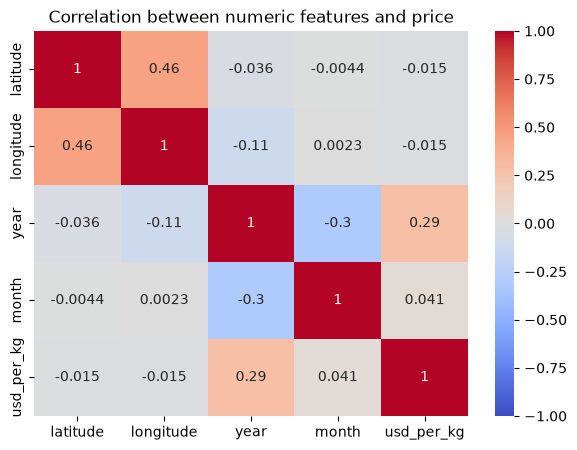

In [6]:
corr = war[["latitude", "longitude", "year", "month", "usd_per_kg"]].corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation between numeric features and price")
plt.show()

### Explanation
Year has the strongest link to price (0.29), because prices kept rising during the war. Latitude, longitude and month are almost unrelated to price on their own, so price must depend mostly on the categorical features like commodity and market. No two features are strongly correlated (the highest is 0.46), so I keep all of them. Year will be my x-axis for the scatter plots later, because it's the feature most correlated with price.

## 7. Distribution of the target

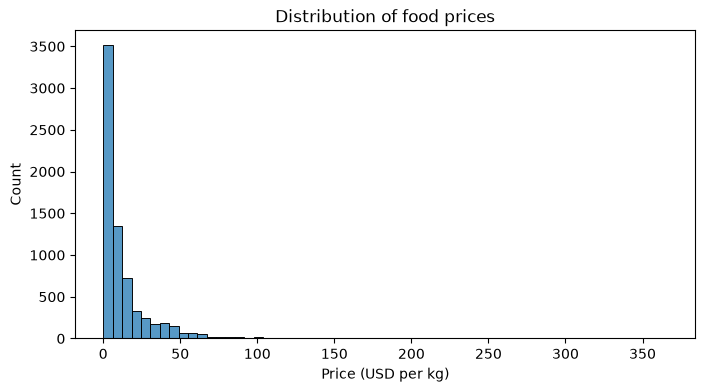

In [7]:
plt.figure(figsize=(8, 4))
sns.histplot(war["usd_per_kg"], bins=60)
plt.xlabel("Price (USD per kg)")
plt.title("Distribution of food prices")
plt.show()

### Explanation
Most prices are below $15 per kg, but there is a long tail of extreme prices up to $366, almost all from Al Fashir and Kadugli during their sieges in 2025. These prices are real, not errors, and they are the markets where aid matters most, so I kept them. I expect the linear models to struggle with these extremes and the tree-based models to handle them better.

## 8. Price by food

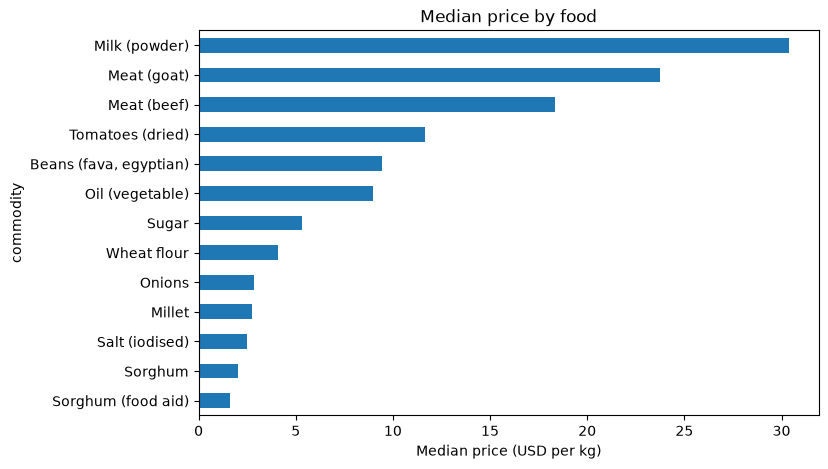

In [8]:
order = war.groupby("commodity")["usd_per_kg"].median().sort_values()
plt.figure(figsize=(8, 5))
order.plot(kind="barh")
plt.xlabel("Median price (USD per kg)")
plt.title("Median price by food")
plt.show()

### Explanation
The type of food changes the price far more than any numeric feature: the median ranges from $1.61 for food-aid sorghum to $30.39 for powdered milk. This shows commodity is the most important feature, so I make sure to keep it and encode it properly.

## 9. Dropping columns

In [9]:
dropped = ["price", "usdprice", "date", "unit", "currency", "priceflag", "admin2", "market_id", "commodity_id"]
data = war.drop(columns=dropped)
X = data.drop(columns="usd_per_kg")
y = data["usd_per_kg"]
print(X.shape, y.shape)
X.head()

(6961, 9) (6961,)


,admin1,market,latitude,longitude,category,commodity,pricetype,year,month
16383,Blue Nile,Damazin,11.79,34.36,cereals and tubers,Millet,Retail,2023,4
16384,Blue Nile,Damazin,11.79,34.36,cereals and tubers,Sorghum,Retail,2023,4
16385,Blue Nile,Damazin,11.79,34.36,cereals and tubers,Wheat flour,Retail,2023,4
16386,Blue Nile,Damazin,11.79,34.36,"meat, fish and eggs",Meat (beef),Retail,2023,4
16387,Blue Nile,Damazin,11.79,34.36,"meat, fish and eggs",Meat (goat),Retail,2023,4


## 10. Most important features

- commodity: the type of food changes the median price from $1.61 to $30.39 
- year: the numeric feature most linked to price (0.29), because prices rose through the war
- market and admin1: the extreme prices come from specific besieged markets (Al Fashir, Kadugli), so location matters 

## 11. Train/test split
80% of the rows are used for training and 20% are kept aside as unseen test data.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(5568, 9) (1393, 9)


## 12. Encoding and scaling
Categorical columns are one-hot encoded and numeric columns are standardized. Both are fitted on the training set only, so no information from the test set leaks into training.

In [11]:
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ("num", StandardScaler(), numeric),
])
X_train_ready = preprocess.fit_transform(X_train)
X_test_ready = preprocess.transform(X_test)
print(X_train_ready.shape, X_test_ready.shape)

(5568, 62) (1393, 62)


# Step two: Train and compare four models